# Random forests: diverse trees, one prediction

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/tree-based/05-random-forests.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A single decision tree can learn useful operating rules, but a small change in its training observations can lead to a different tree. In this notebook, we use many such trees to predict whether a gas-turbine operating observation receives the positive `high_co` label.

We will first use **bagging** to average trees fitted to bootstrap samples. A **random forest** adds another source of diversity: at each split, each tree may consider only a random subset of the available features.

## What you will do

1. Compare one fully grown tree with bagging and a random forest on the same held-out data.
2. Inspect how random feature subsets make the trees less alike.
3. Watch the ensemble prediction stabilize as more trees are averaged.

**Estimated time:** 40–50 minutes

In [1]:
from pathlib import Path
from typing import Any
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
deep_palette = sns.color_palette("deep")
single_tree_color, bagging_color, forest_color = deep_palette[:3]

## 1. Set up the classification task

We continue using the nine measured operating quantities and the same 70/30 stratified train/test split used in the earlier tree lessons. `high_co` is the binary target; `CO` itself is excluded because that measurement defines the label.

Trees choose cutpoints based on the ordering of a feature's values, so unlike gradient-based models, they do not require feature standardization.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/changyaochen/MECE4520/master/"
    "site/data/gas-turbine-course.csv"
)
data_candidates = [
    Path("../data/gas-turbine-course.csv"),
    Path("site/data/gas-turbine-course.csv"),
    Path("gas-turbine-course.csv"),
]
data_path = next((path for path in data_candidates if path.exists()), data_candidates[-1])

# In Google Colab, retrieve the course dataset only when it is not already present.
if not data_path.exists():
    urlretrieve(url=DATA_URL, filename=data_path)

FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGET = "high_co"
RANDOM_STATE = 4520

data = pd.read_csv(filepath_or_buffer=data_path)
model_data = data[FEATURES + [TARGET]].dropna().copy()

X_train, X_test, y_train, y_test = train_test_split(
    model_data[FEATURES],
    model_data[TARGET],
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=model_data[TARGET],
)

split_summary = pd.DataFrame(
    {
        "observations": [len(X_train), len(X_test)],
        "positive-label fraction": [y_train.mean(), y_test.mean()],
    },
    index=["Training set", "Test set"],
)
split_summary.style.format({"positive-label fraction": "{:.1%}"})

,observations,positive-label fraction
Training set,24778,38.8%
Test set,10620,38.8%


## 2. Begin with one fully grown tree

We deliberately allow the first tree to keep splitting until its terminal regions are pure whenever possible. This makes it flexible, but also sensitive to the particular observations it saw. ROC AUC lets us compare the probability rankings on the training and held-out test sets.

In [3]:
def auc_scores(*, model: Any, X_train: pd.DataFrame, y_train: pd.Series, X_test: pd.DataFrame, y_test: pd.Series) -> dict[str, float]:
    """Compute training and held-out ROC AUC for a fitted classifier.

    Args:
        model: A fitted classifier that provides ``predict_proba``.
        X_train: Features used to fit the model.
        y_train: Training labels.
        X_test: Held-out feature values.
        y_test: Held-out labels.

    Returns:
        A dictionary containing training and test ROC AUC values.
    """
    training_probability = model.predict_proba(X_train)[:, 1]
    test_probability = model.predict_proba(X_test)[:, 1]

    return {
        "training AUC": roc_auc_score(y_train, training_probability),
        "test AUC": roc_auc_score(y_test, test_probability),
    }


single_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
single_tree.fit(X=X_train, y=y_train)

single_tree_scores = auc_scores(
    model=single_tree,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
)
pd.DataFrame([single_tree_scores], index=["One fully grown tree"]).round(3)

,training AUC,test AUC
One fully grown tree,1.0,0.833


The perfect training AUC is a warning, not an achievement: this tree has enough flexibility to memorize its training observations. Next, rather than asking one tree to be stable, we will average many unstable trees.

## 3. Bagging: vary the observations, then average

A **bootstrap sample** contains the same number of rows as the training set, sampled with replacement. Some observations therefore appear more than once, while others are omitted. Bagging fits one tree to each bootstrap sample.

For a new operating point \(\mathbf{x}\), we average the positive-label probabilities from \(B\) trees:

$$
\hat p_{\mathrm{ensemble}}(\mathbf{x}) = \frac{1}{B} \sum_{b=1}^{B} \hat p_b(\mathbf{x}).
$$

In [4]:
rng = np.random.default_rng(seed=RANDOM_STATE)
bootstrap_indices = rng.integers(low=0, high=len(X_train), size=len(X_train))
unique_rows = np.unique(bootstrap_indices).size

print(f"Rows in one bootstrap sample: {len(bootstrap_indices):,}")
print(f"Distinct training rows represented: {unique_rows:,} ({unique_rows / len(X_train):.1%})")

Rows in one bootstrap sample: 24,778
Distinct training rows represented: 15,605 (63.0%)


In [5]:
N_TREES = 200

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=N_TREES,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
bagging.fit(X=X_train, y=y_train)

bagging_scores = auc_scores(
    model=bagging,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
)
pd.DataFrame([bagging_scores], index=[f"Bagging ({N_TREES} trees)"]).round(3)

,training AUC,test AUC
Bagging (200 trees),1.0,0.947


## 4. Random forests: vary observations *and* feature competition

Bagging gives each tree a different bootstrap sample, but every split may still consider all nine features. If one feature is especially attractive, many trees can make very similar early decisions. A random forest breaks that pattern by drawing a fresh subset of feature candidates at **every split**.

For classification, a common default is \(m=\sqrt{p}\) candidates per split. Here \(p=9\), so each split considers three randomly drawn features.

| Method | Observations used by each tree | Feature candidates at each split |
| --- | --- | --- |
| One tree | Full training set | All 9 features |
| Bagging | Bootstrap sample | All 9 features |
| Random forest | Bootstrap sample | Random 3 of 9 features |

In [6]:
random_forest = RandomForestClassifier(
    n_estimators=N_TREES,
    max_features="sqrt",
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
random_forest.fit(X=X_train, y=y_train)

random_forest_scores = auc_scores(
    model=random_forest,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
)

comparison = pd.DataFrame(
    [single_tree_scores, bagging_scores, random_forest_scores],
    index=["One fully grown tree", f"Bagging ({N_TREES} trees)", f"Random forest ({N_TREES} trees)"],
)
comparison.round(3)

,training AUC,test AUC
One fully grown tree,1.0,0.833
Bagging (200 trees),1.0,0.947
Random forest (200 trees),1.0,0.948


## 5. Do random feature subsets make trees less alike?

One practical way to compare tree similarity is to correlate their predicted probabilities across the same held-out observations. This is not exactly the idealized \(\rho\) from the ensemble-variance formula, but it is a useful proxy: highly similar predictions imply highly correlated trees.

We also inspect the root feature selected by each tree. In bagging, a dominant feature can win at the root of nearly every tree. In a random forest, the feature draw sometimes prevents that feature from competing at all.

In [7]:
def individual_tree_probabilities(*, model: Any, X: pd.DataFrame) -> np.ndarray:
    """Collect positive-label probabilities from every tree in an ensemble.

    Args:
        model: A fitted bagging or random-forest classifier.
        X: Feature values to score.

    Returns:
        An array with one row per observation and one column per tree.
    """
    X_values = X.to_numpy()
    return np.column_stack(
        [tree.predict_proba(X_values)[:, 1] for tree in model.estimators_]
    )


def pairwise_tree_correlations(*, probabilities: np.ndarray) -> np.ndarray:
    """Return all unique pairwise correlations among ensemble trees.

    Args:
        probabilities: One predicted-probability column per tree.

    Returns:
        The upper-triangle correlations, excluding the diagonal.
    """
    correlation_matrix = np.corrcoef(probabilities, rowvar=False)
    upper_triangle = np.triu_indices_from(correlation_matrix, k=1)
    return correlation_matrix[upper_triangle]


def root_feature_names(*, model: Any, feature_names: list[str]) -> list[str]:
    """Read the feature selected at the root of every fitted tree.

    Args:
        model: A fitted ensemble whose estimators are decision trees.
        feature_names: Feature names in the order supplied to the model.

    Returns:
        The root-split feature from each tree.
    """
    return [feature_names[int(tree.tree_.feature[0])] for tree in model.estimators_]


bagging_tree_probabilities = individual_tree_probabilities(model=bagging, X=X_test)
forest_tree_probabilities = individual_tree_probabilities(model=random_forest, X=X_test)

bagging_correlations = pairwise_tree_correlations(probabilities=bagging_tree_probabilities)
forest_correlations = pairwise_tree_correlations(probabilities=forest_tree_probabilities)

bagging_roots = root_feature_names(model=bagging, feature_names=FEATURES)
forest_roots = root_feature_names(model=random_forest, feature_names=FEATURES)

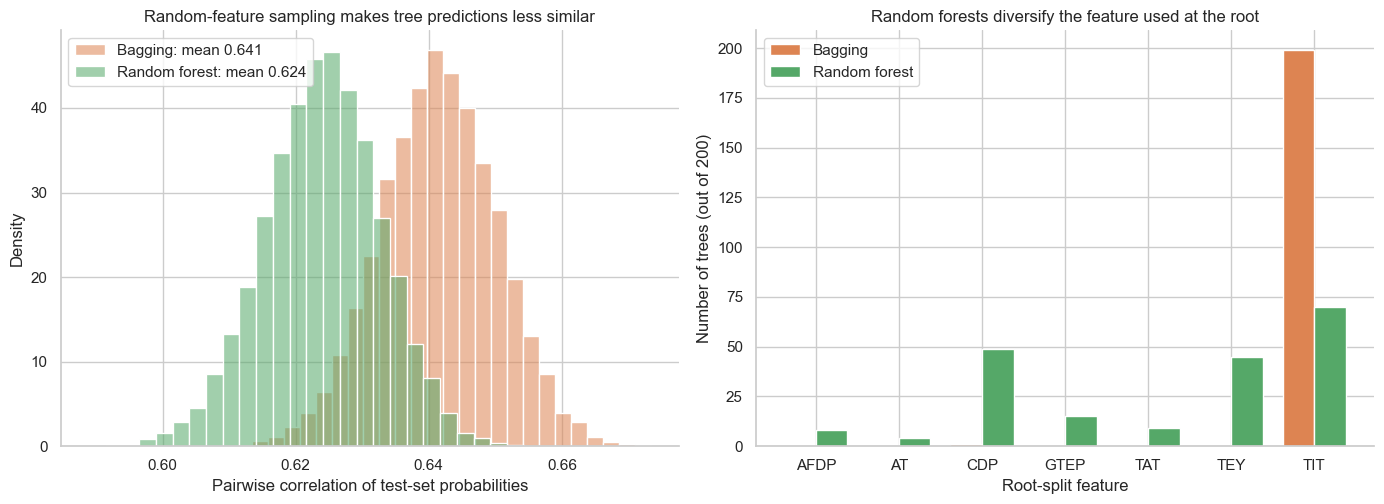

In [8]:
root_order = sorted(set(bagging_roots) | set(forest_roots))
bagging_root_counts = pd.Series(bagging_roots).value_counts().reindex(root_order, fill_value=0)
forest_root_counts = pd.Series(forest_roots).value_counts().reindex(root_order, fill_value=0)

fig, axes = plt.subplots(ncols=2, figsize=(14, 5.2))

sns.histplot(
    bagging_correlations,
    bins=28,
    stat="density",
    color=bagging_color,
    alpha=0.55,
    label=f"Bagging: mean {bagging_correlations.mean():.3f}",
    ax=axes[0],
)
sns.histplot(
    forest_correlations,
    bins=28,
    stat="density",
    color=forest_color,
    alpha=0.55,
    label=f"Random forest: mean {forest_correlations.mean():.3f}",
    ax=axes[0],
)
axes[0].set(
    title="Random-feature sampling makes tree predictions less similar",
    xlabel="Pairwise correlation of test-set probabilities",
    ylabel="Density",
)
axes[0].legend()

positions = np.arange(len(root_order))
bar_width = 0.38
axes[1].bar(positions - bar_width / 2, bagging_root_counts, width=bar_width, color=bagging_color, label="Bagging")
axes[1].bar(positions + bar_width / 2, forest_root_counts, width=bar_width, color=forest_color, label="Random forest")
axes[1].set(
    title="Random forests diversify the feature used at the root",
    xlabel="Root-split feature",
    ylabel=f"Number of trees (out of {N_TREES})",
    xticks=positions,
    xticklabels=root_order,
)
axes[1].legend()

sns.despine(fig=fig)
fig.tight_layout()
plt.show()

## 6. Watch the ensemble stabilize

The next calculation averages the first 1, 2, 3, and eventually all \(B\) trees. The order is one reproducible random ordering of the fitted trees, so the early part of each curve can wiggle. The larger lesson is that both ensembles settle as more tree predictions are averaged.

Adding trees is not the same as making an individual tree more complex. Once a forest is large enough, adding more trees usually stabilizes performance rather than causing the usual single-tree overfitting pattern.

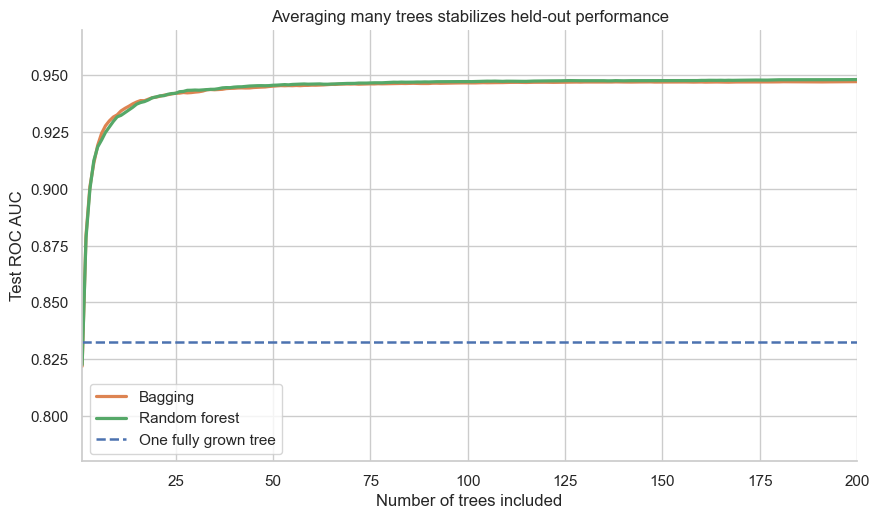

In [9]:
def cumulative_test_auc(*, probabilities: np.ndarray, labels: pd.Series) -> np.ndarray:
    """Compute held-out AUC after successively averaging more trees.

    Args:
        probabilities: One test-set probability column per tree.
        labels: Held-out binary labels.

    Returns:
        AUC values for ensembles containing 1 through all fitted trees.
    """
    tree_counts = np.arange(1, probabilities.shape[1] + 1)
    running_probability = np.cumsum(probabilities, axis=1) / tree_counts
    return np.array(
        [roc_auc_score(labels, running_probability[:, index]) for index in range(probabilities.shape[1])]
    )


bagging_auc_curve = cumulative_test_auc(probabilities=bagging_tree_probabilities, labels=y_test)
forest_auc_curve = cumulative_test_auc(probabilities=forest_tree_probabilities, labels=y_test)
tree_counts = np.arange(1, N_TREES + 1)

fig, axis = plt.subplots(figsize=(10, 5.6))
axis.plot(tree_counts, bagging_auc_curve, color=bagging_color, linewidth=2.3, label="Bagging")
axis.plot(tree_counts, forest_auc_curve, color=forest_color, linewidth=2.3, label="Random forest")
axis.axhline(
    single_tree_scores["test AUC"],
    color=single_tree_color,
    linestyle="--",
    linewidth=1.8,
    label="One fully grown tree",
)
axis.set(
    title="Averaging many trees stabilizes held-out performance",
    xlabel="Number of trees included",
    ylabel="Test ROC AUC",
    xlim=(1, N_TREES),
    ylim=(0.78, 0.97),
)
axis.legend()
sns.despine(ax=axis)
plt.show()

## 7. One operating observation, many tree opinions

To make disagreement visible, we select one held-out observation whose final random-forest probability is closest to 0.50. It is not a special observation used to fit or choose the model; it is simply a useful case for seeing individual tree votes.

Because the trees are fully grown, most individual tree probabilities are 0 or 1. Their running mean is the ensemble's positive-label probability.

Observed label: 1
Bagging probability after 200 trees: 0.490
Random-forest probability after 200 trees: 0.500


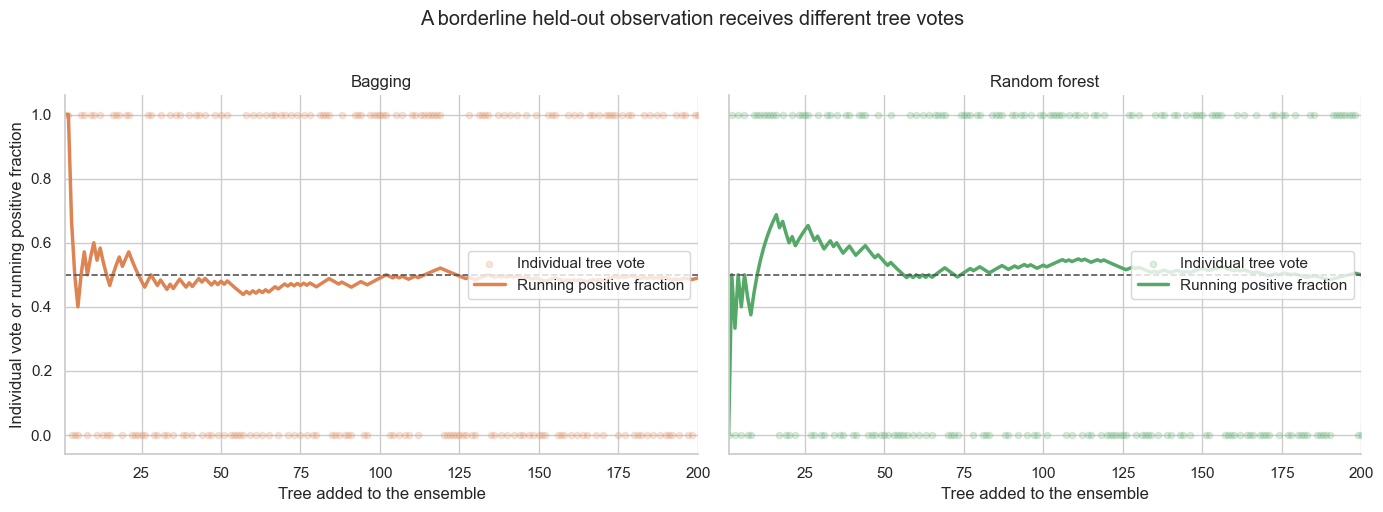

In [10]:
forest_test_probability = random_forest.predict_proba(X_test)[:, 1]
example_position = int(np.argmin(np.abs(forest_test_probability - 0.50)))
example_label = int(y_test.iloc[example_position])

example_bagging_votes = bagging_tree_probabilities[example_position]
example_forest_votes = forest_tree_probabilities[example_position]

print(f"Observed label: {example_label}")
print(f"Bagging probability after {N_TREES} trees: {example_bagging_votes.mean():.3f}")
print(f"Random-forest probability after {N_TREES} trees: {example_forest_votes.mean():.3f}")

fig, axes = plt.subplots(ncols=2, figsize=(14, 5.0), sharey=True)
for axis, votes, color, title in [
    (axes[0], example_bagging_votes, bagging_color, "Bagging"),
    (axes[1], example_forest_votes, forest_color, "Random forest"),
]:
    numbers = np.arange(1, N_TREES + 1)
    running_mean = np.cumsum(votes) / numbers
    axis.scatter(numbers, votes, color=color, alpha=0.20, s=20, label="Individual tree vote")
    axis.plot(numbers, running_mean, color=color, linewidth=2.5, label="Running positive fraction")
    axis.axhline(0.50, color="#555555", linestyle="--", linewidth=1.2)
    axis.set(
        title=title,
        xlabel="Tree added to the ensemble",
        xlim=(1, N_TREES),
        ylim=(-0.06, 1.06),
    )
    axis.legend(loc="center right")

axes[0].set_ylabel("Individual vote or running positive fraction")
fig.suptitle("A borderline held-out observation receives different tree votes", y=1.02)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

## Takeaways

- A single deep tree can memorize the training observations; averaging bootstrap trees makes its predictions much more stable.
- Bagging varies the observations available to each tree. A random forest also varies which features compete at each split.
- Lower similarity among the trees makes averaging more effective.
- A random forest predicts a positive-label probability by averaging the individual tree probabilities.

Next, open the interactive explorer to watch an actual forest add one tree at a time.

[Open the random-forest explorer](06-random-forest-explorer.qmd)  
[Return to Tree-based](index.qmd)